# **Classification Project: German Credit Risk Prediction**

# **Marks: 100**

Welcome to the classification project.

In this project, you will build machine learning models to predict whether a credit applicant is a **good** or **bad** credit risk.

---
## **Objective**
---
The objective of this project is to:
- Perform exploratory data analysis (EDA)
- Apply proper preprocessing using Pipelines
- Build and tune classification models
- Compare models and justify a final recommendation


---
## **Dataset Description**
---
We use the **German Credit dataset (credit-g, OpenML id 31)**.

Each row represents a loan applicant described by a mixture of numerical and categorical features.

Target variable:
- `good` = 0
- `bad` = 1

You will load the dataset using `fetch_openml`.


## **Importing the necessary libraries**

In [2]:

# TODO: Import necessary libraries

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.compose import ColumnTransformer, make_column_selector as selector
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

np.random.seed(42)


## **Task 0: Loading the Dataset**

In [3]:
#This imports all the data
Xy = fetch_openml(data_id=31, as_frame=True)

#Here we have the features of each client, the coumns being features and each row representing a new person
X = Xy.data

#gives output of either a good or bad credit score for each customer
y_raw = Xy.target


# Sets numeric labels for good or bad credit score, since linear models can only interpret numeric values rather than strings
y = y_raw.map({'good': 0, 'bad': 1})



---
## **Task 1: Data Overview**

- Inspect dataset shape and target class distribution.
- Summarize numeric features (mean, std, min/max) and visualize selected distributions.
- Discuss missing values (if any) and potential preprocessing needs.
---
- Number of observations
- Number of features
- Class distribution
- Check for missing values


In [4]:

#Data set shape: How many rows (Data points) and columns (Features)
row, col = X.shape

print("There are", col,"features and", row, "data points, specifically each client in the credit system")



There are 20 features and 1000 data points, specifically each client in the credit system


In [5]:
#Names of all features
print("These are all the features: ")
print(list(X.columns))

These are all the features: 
['checking_status', 'duration', 'credit_history', 'purpose', 'credit_amount', 'savings_status', 'employment', 'installment_commitment', 'personal_status', 'other_parties', 'residence_since', 'property_magnitude', 'age', 'other_payment_plans', 'housing', 'existing_credits', 'job', 'num_dependents', 'own_telephone', 'foreign_worker']


In [6]:
#
print(X.describe())

          duration  credit_amount  installment_commitment  residence_since  \
count  1000.000000    1000.000000             1000.000000      1000.000000   
mean     20.903000    3271.258000                2.973000         2.845000   
std      12.058814    2822.736876                1.118715         1.103718   
min       4.000000     250.000000                1.000000         1.000000   
25%      12.000000    1365.500000                2.000000         2.000000   
50%      18.000000    2319.500000                3.000000         3.000000   
75%      24.000000    3972.250000                4.000000         4.000000   
max      72.000000   18424.000000                4.000000         4.000000   

               age  existing_credits  num_dependents  
count  1000.000000       1000.000000     1000.000000  
mean     35.546000          1.407000        1.155000  
std      11.375469          0.577654        0.362086  
min      19.000000          1.000000        1.000000  
25%      27.000000    

In [7]:
#Check which features are numerical and which are categorical, (feature types)
X.dtypes

,0
checking_status,category
duration,int64
credit_history,category
purpose,category
credit_amount,int64
savings_status,category
employment,category
installment_commitment,int64
personal_status,category
other_parties,category


In [8]:
#Display of the first few rows
X.head()

,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes


In [9]:
#Class distribution: Good = 0 , Bad = 1
y.value_counts()
#from this we can see that there are 700 good credit scores and 300 bad credit scores



,count
class,
0,700
1,300


In [10]:

#Checking for missing values
print(X.isnull().sum())

print("There are no missing values in the data set")

checking_status           0
duration                  0
credit_history            0
purpose                   0
credit_amount             0
savings_status            0
employment                0
installment_commitment    0
personal_status           0
other_parties             0
residence_since           0
property_magnitude        0
age                       0
other_payment_plans       0
housing                   0
existing_credits          0
job                       0
num_dependents            0
own_telephone             0
foreign_worker            0
dtype: int64
There are no missing values in the data set


---
## **Exploratory Data Analysis (EDA)**
---
EDA is crucial before building models. Investigate distributions and relationships.

**Questions to guide your analysis:**
1. Is the dataset imbalanced?
- There are 700 good credit scores while only 300 bad ones. This gives a bit of imbalance for the outcome.
2. What do the distributions of key numeric features look like?
- Most credit amount is between 0 and 5000.
3. Are there noticeable differences between good and bad applicants?
- Bad credit score applicants have a longer duration aswell as a larger credit amount
- Good credit score applicants are on average older
4. What preprocessing steps seem necessary based on your observations?
- Visually, the only numeric features giving clues are the age,


/tmp/ipykernel_2690/3087571631.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x=y, palette="pastel")


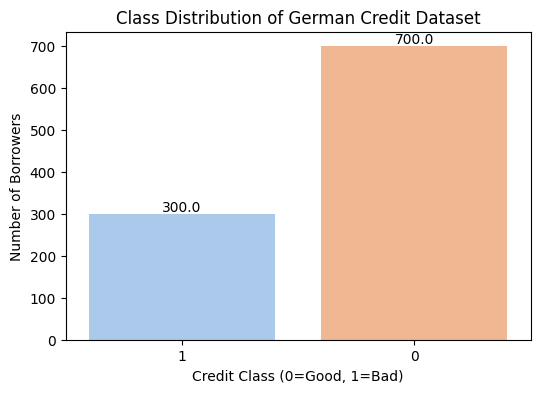

In [11]:
# Plot class distribution

plt.figure(figsize=(6,4))
ax = sns.countplot(x=y, palette="pastel")

# Add counts on top of each bar
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height}',
                xy=(p.get_x() + p.get_width()/2, height),
                ha='center',
                va='bottom',
                fontsize=10)

plt.xlabel("Credit Class (0=Good, 1=Bad)")
plt.ylabel("Number of Borrowers")
plt.title("Class Distribution of German Credit Dataset")
plt.show()

#There are more good credit scores than there are bad ones



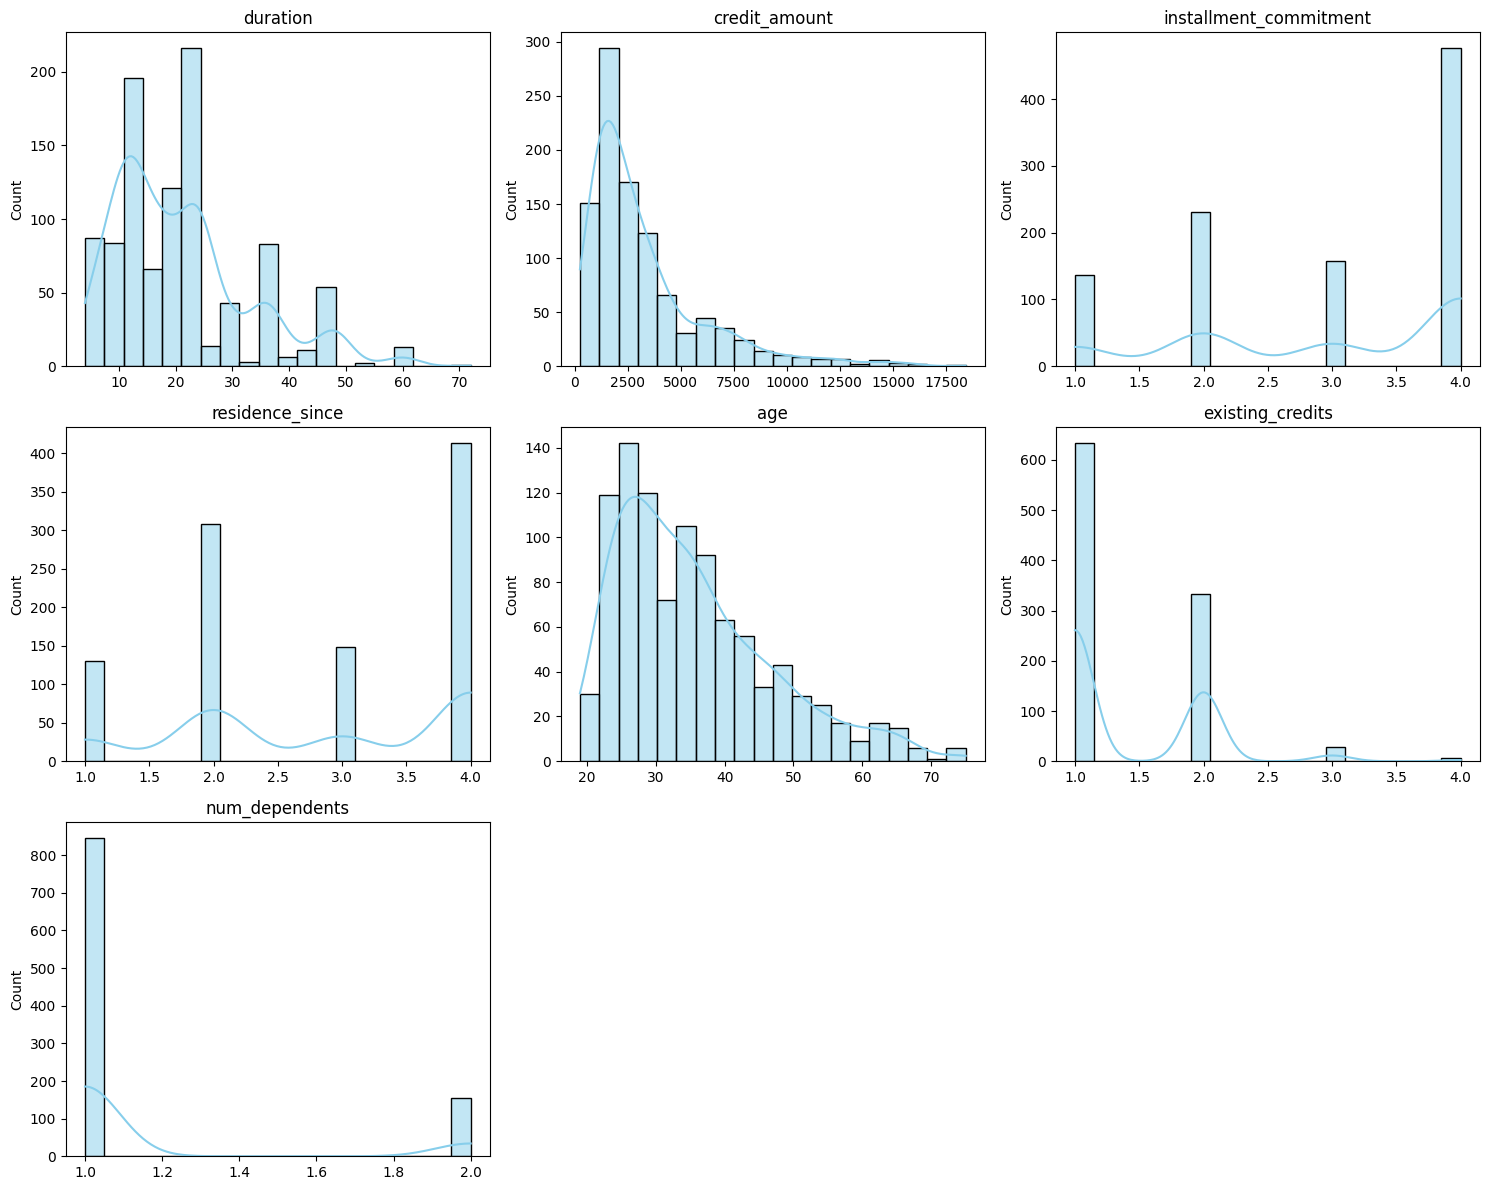

In [12]:
# Plot histograms for selected numeric features
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns

# Determine number of subplots
num_features = len(numeric_features)
cols = 3  # number of columns in grid
rows = (num_features + cols - 1) // cols  # compute rows needed

plt.figure(figsize=(cols*5, rows*4))  # adjust figure size

for i, col in enumerate(numeric_features):
    plt.subplot(rows, cols, i+1)
    sns.histplot(X[col], kde=True, bins=20, color='skyblue')
    plt.title(col)
    plt.xlabel('')
    plt.ylabel('Count')

plt.tight_layout()
plt.show()

/tmp/ipykernel_2690/2673397571.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=X[col], palette="pastel")  # hue=y is equivalent to x=y here
/tmp/ipykernel_2690/2673397571.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=X[col], palette="pastel")  # hue=y is equivalent to x=y here
/tmp/ipykernel_2690/2673397571.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=y, y=X[col], palette="pastel")  # hue=y is equivalent to x=y here
/tmp/ipykernel_2690/2673397571.py:12: FutureWarning: 

Passing `palette` without assigning 

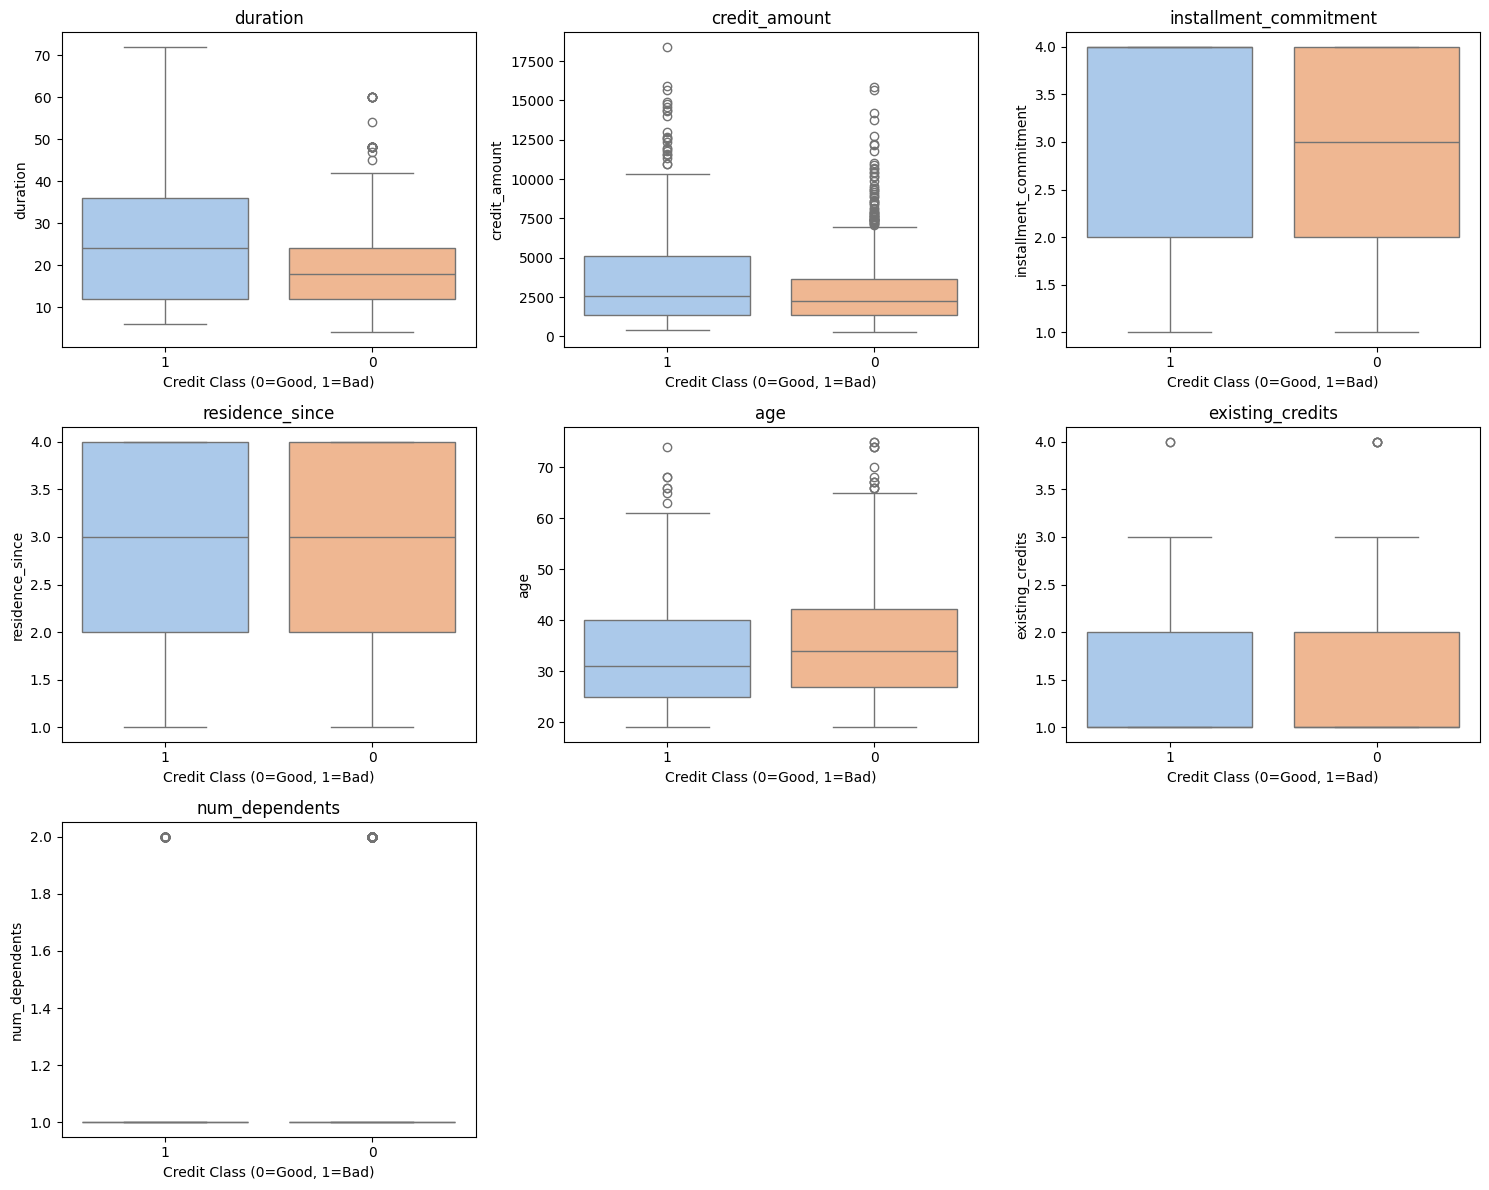

In [13]:
# TODO: Boxplots of numeric features by class

# Grid layout
num_features = len(numeric_features)
cols = 3
rows = (num_features + cols - 1) // cols

plt.figure(figsize=(cols*5, rows*4))

for i, col in enumerate(numeric_features):
    plt.subplot(rows, cols, i+1)
    sns.boxplot(x=y, y=X[col], palette="pastel")  # hue=y is equivalent to x=y here
    plt.title(col)
    plt.xlabel("Credit Class (0=Good, 1=Bad)")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

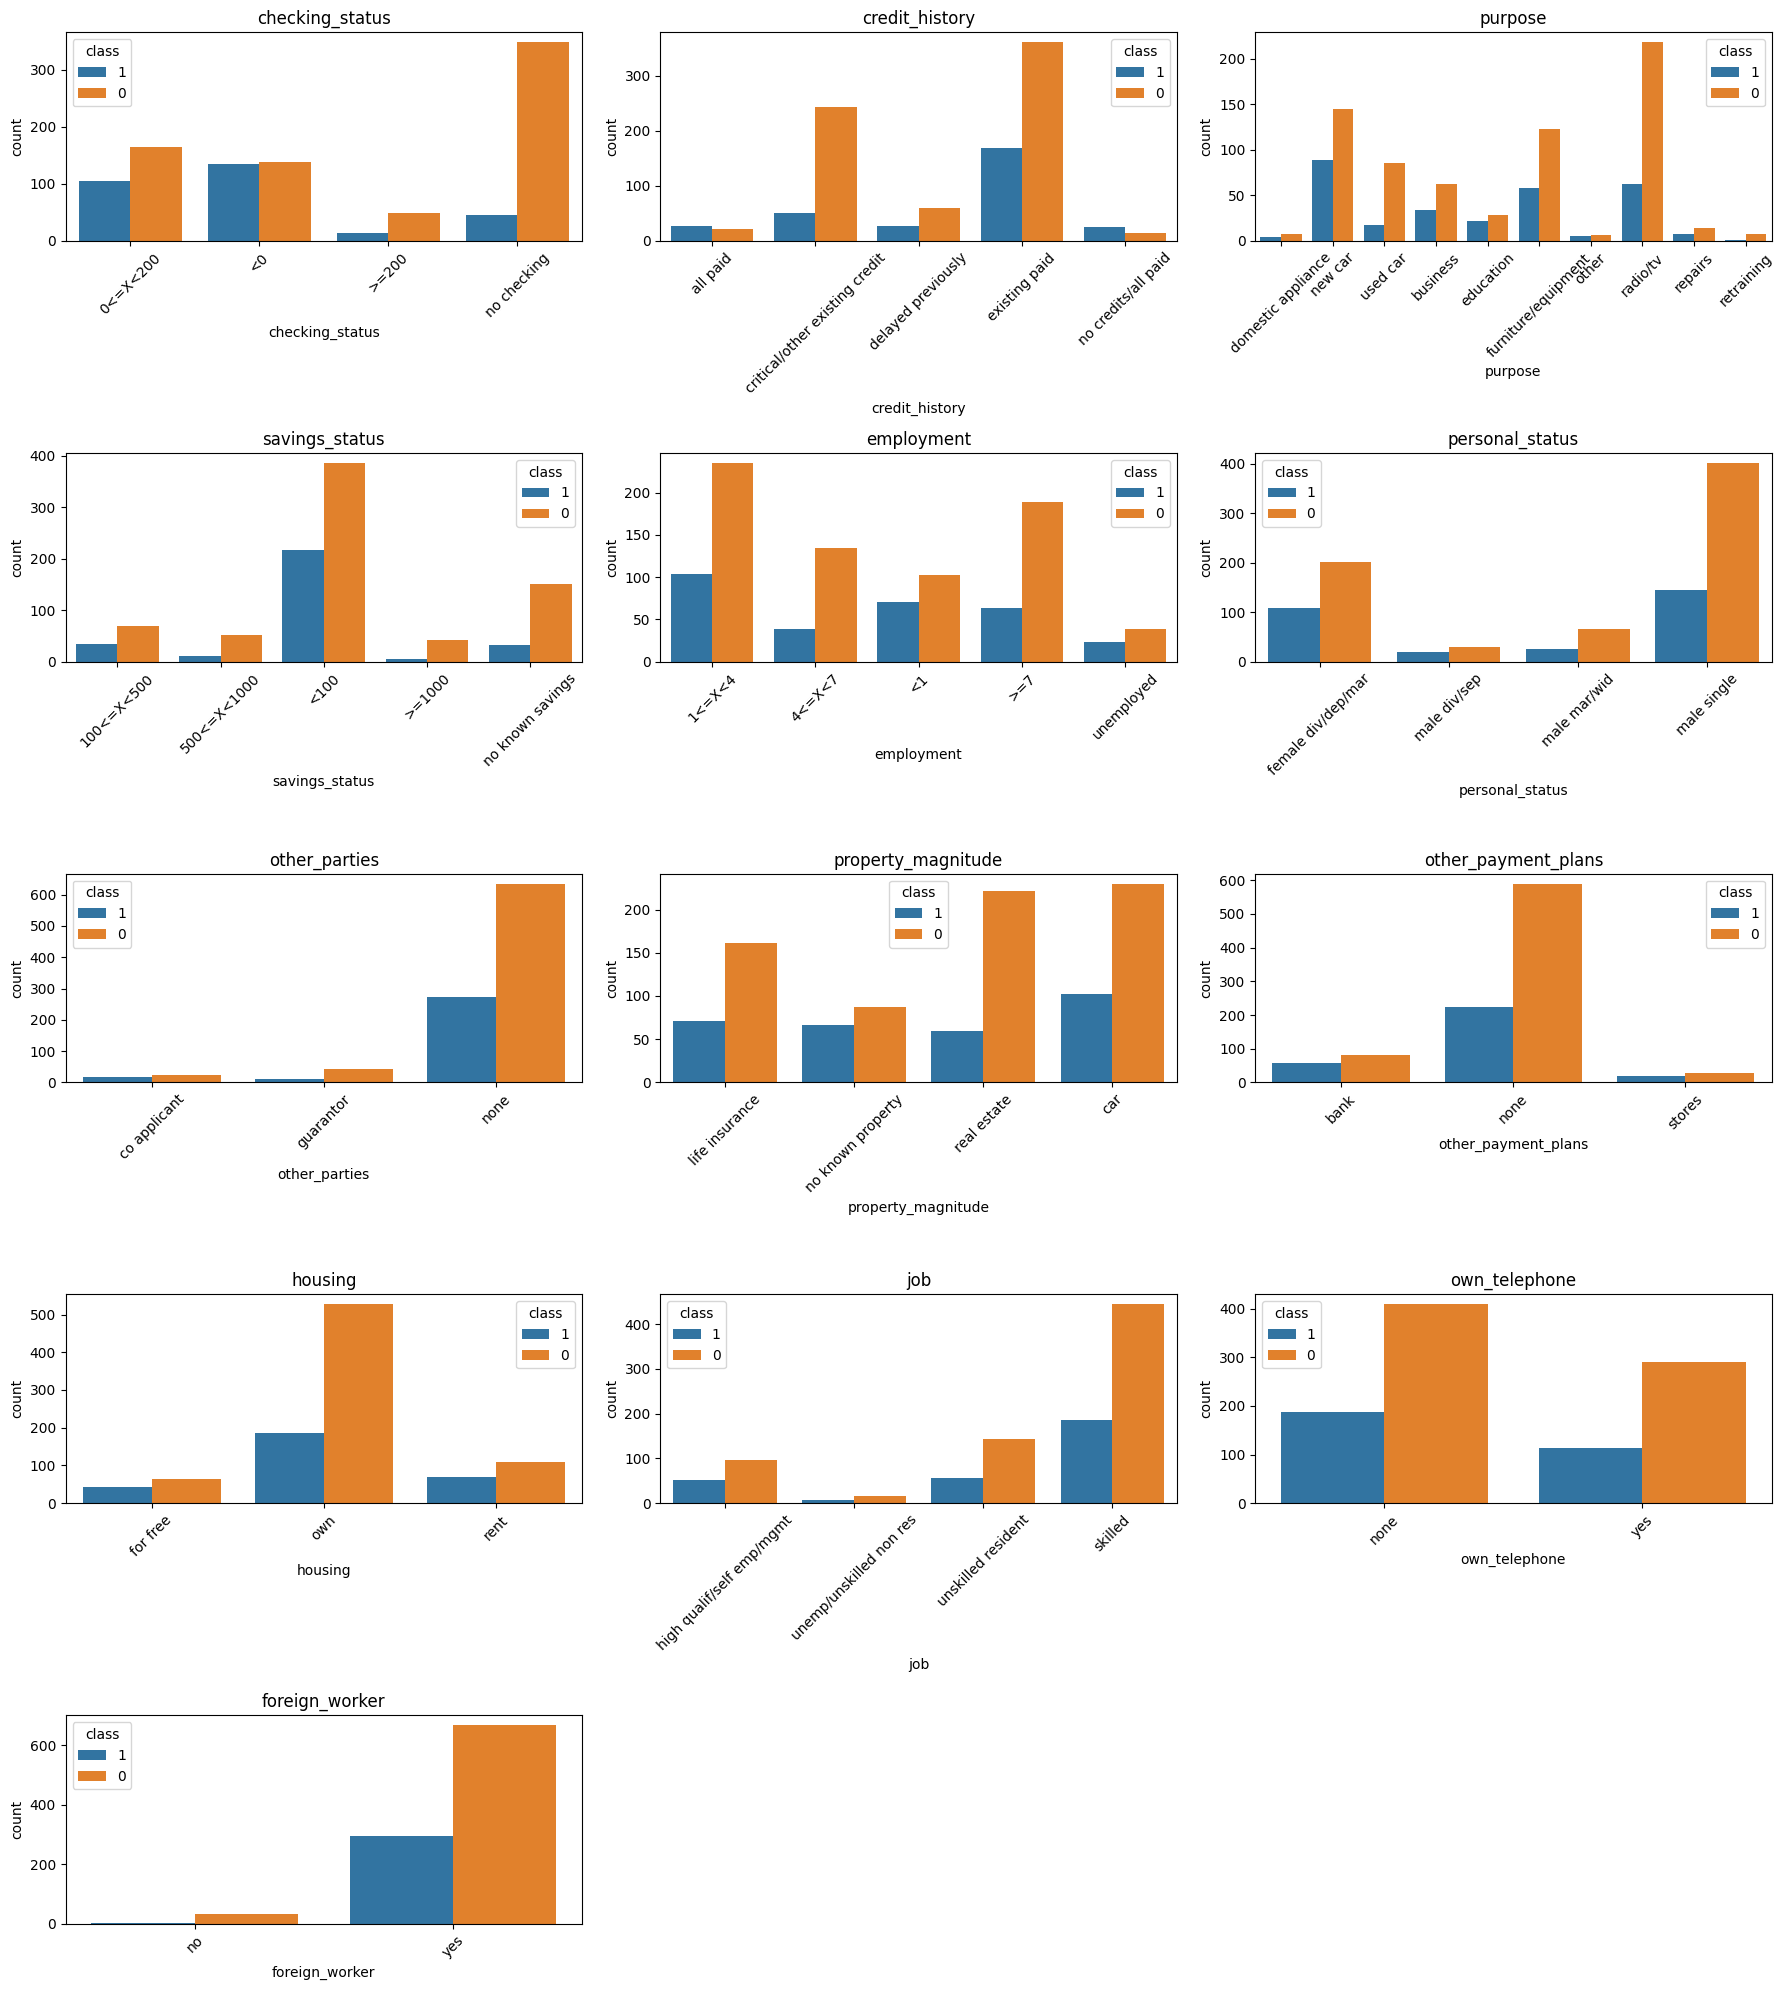

In [14]:
# TODO: Explore one categorical feature vs target
# select categorical columns
cat_cols = X.select_dtypes(include=['object', 'category']).columns

# define subplot grid
n_cols = 3
n_rows = (len(cat_cols) + n_cols - 1) // n_cols

plt.figure(figsize=(n_cols*6, n_rows*4))

for i, col in enumerate(cat_cols):
    plt.subplot(n_rows, n_cols, i+1)
    sns.countplot(x=X[col], hue = y)
    plt.title(col)
    plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

---
## **Data Preprocessing**
---
- Split into train and test sets (use stratification)
- Keep the test set untouched until final evaluation
- Use Pipeline + ColumnTransformer
- Scale numerical features
- One-hot encode categorical features


In [15]:

#Train/test split with stratification
#Since the dataset is of moderate size (1000 samples), an 80/20 split is appropriate to ensure both sufficient training data and a reliable test set

X_train, X_test, y_train, y_test = train_test_split(
    X,               # features
    y,               # target
    test_size=0.2,   # 20% of data for the test set
    random_state=28,
    stratify=y       # keeps the class proportions the same in train/test
)


# Define numeric and categorical pipelines
numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns
categorical_features = X_train.select_dtypes(include=['object', 'category']).columns

numeric_pipeline = Pipeline([
    ('scaler', StandardScaler())])

categorical_pipeline = Pipeline([
    ('encoder', OneHotEncoder(handle_unknown='ignore')) #adds one hot coder to categorical feature, avoiding artificial ordering
])

#Combine using ColumnTransformer
preprocessor = ColumnTransformer([
    ('num', numeric_pipeline, numeric_features),
    ('cat', categorical_pipeline, categorical_features)
])

pass


---
## **Conceptual Question: Perceptron (No Implementation)**
---
Answer the following in markdown:

1. What assumptions does the Perceptron make?
- The Perceptron assumes that the data is linearly separable, meaning that there exists a linear decision boundary (a hyperplane) that can perfectly separate the classes.
2. When is convergence guaranteed?
- if there is a positive margin, the Perceptron algorithm will find a solution in a finite number of updates.
3. Is it likely appropriate for this dataset? Why or why not?
- It is not very appropriate for this dataset. The German Credit Dataset contains a mix of categorical and numerical features and represents a real-world problem, which is typically not linearly separable.


---
## **Model Building: Linear Models**
---
You will build and tune:
- Logistic Regression
- Linear SVM

Use cross-validation on the training set to tune `C`.


Best parameter C: {'classifier__C': 0.1}
Best CV score: 0.7575
Test accuracy: 0.775


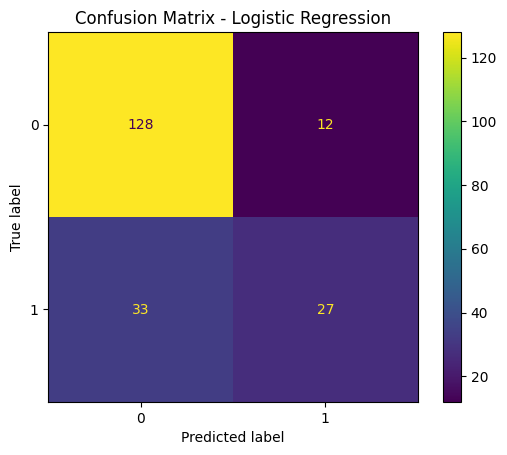

In [16]:

# 1 pipeline

model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000))
])


# tune C
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]
}

grid_search = GridSearchCV(
    model,
    param_grid,
    cv=5,              # 5-fold cross-validation
    scoring='accuracy'
)

# Fit on training data only
grid_search.fit(X_train, y_train)

print("Best parameter C:", grid_search.best_params_)
print("Best CV score:", grid_search.best_score_)


# evaluate with test set

best_model = grid_search.best_estimator_

y_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Test accuracy:", accuracy)


# Confusion Matrix to evaluate performance
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()



Best parameter C: {'classifier__C': 0.1}
Best CV score: 0.7612500000000001
Test accuracy: 0.785


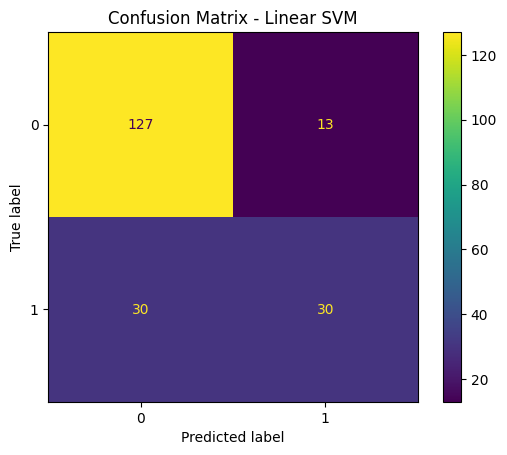

In [17]:


# Build full pipeline

svm_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', LinearSVC(max_iter=5000))  # linear SVM
])


# C

param_grid_svm = {
    'classifier__C': [0.01, 0.1, 1, 10, 100]  # regularization strength
}

grid_search_svm = GridSearchCV(
    svm_model,
    param_grid_svm,
    cv=5,              # 5-fold cross-validation
    scoring='accuracy'
)

# Fit on training data only
grid_search_svm.fit(X_train, y_train)

print("Best parameter C:", grid_search_svm.best_params_)
print("Best CV score:", grid_search_svm.best_score_)


# 3. Evaluate on test set

best_svm = grid_search_svm.best_estimator_

y_pred_svm = best_svm.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
print("Test accuracy:", accuracy_svm)

# 4. Confusion Matrix

cm_svm = confusion_matrix(y_test, y_pred_svm)

disp_svm = ConfusionMatrixDisplay(confusion_matrix=cm_svm)
disp_svm.plot()
plt.title("Confusion Matrix - Linear SVM")
plt.show()

pass


---
## **Model Building: k-Nearest Neighbors (kNN)**
---
Tune the number of neighbors and evaluate performance.


Best n_neighbors: {'classifier__n_neighbors': 7}
Best CV score: 0.74
Test accuracy: 0.735


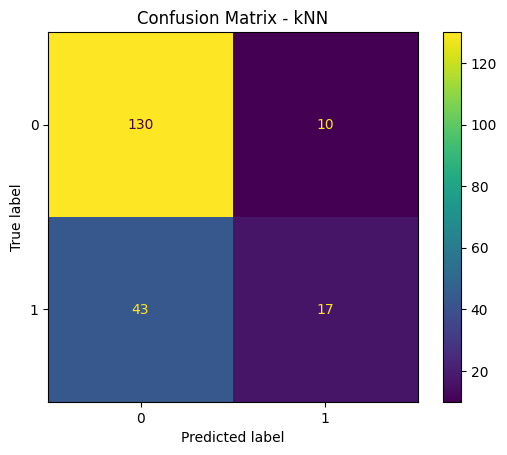

In [20]:



knn_model = Pipeline([
    ('preprocessing', preprocessor),
    ('classifier', KNeighborsClassifier())
])


param_grid_knn = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11]  # number of neighbors to test
}

grid_search_knn = GridSearchCV(
    knn_model,
    param_grid_knn,
    cv=5,              # 5-fold cross-validation
    scoring='accuracy'
)

grid_search_knn.fit(X_train, y_train)

print("Best n_neighbors:", grid_search_knn.best_params_)
print("Best CV score:", grid_search_knn.best_score_)


best_knn = grid_search_knn.best_estimator_

y_pred_knn = best_knn.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
print("Test accuracy:", accuracy_knn)


cm_knn = confusion_matrix(y_test, y_pred_knn)

disp_knn = ConfusionMatrixDisplay(confusion_matrix=cm_knn)
disp_knn.plot()
plt.title("Confusion Matrix - kNN")
plt.show()

pass


---
## **Model Performance Comparison**
---
- Compare Accuracy, Precision, Recall, and F1-score
- Interpret confusion matrices
- Which model performs best and why?


In [21]:

precision_lr = precision_score(y_test, y_pred)
recall_lr = recall_score(y_test, y_pred)
f1_lr = f1_score(y_test, y_pred)

precision_svm = precision_score(y_test, y_pred_svm)
recall_svm = recall_score(y_test, y_pred_svm)
f1_svm = f1_score(y_test, y_pred_svm)


precision_knn = precision_score(y_test, y_pred_knn)
recall_knn = recall_score(y_test, y_pred_knn)
f1_knn = f1_score(y_test, y_pred_knn)


results = pd.DataFrame({
    'Model': ['Logistic Regression', 'Linear SVM', 'kNN'],
    'Best Parameter': [
        grid_search.best_params_['classifier__C'],
        grid_search_svm.best_params_['classifier__C'],
        grid_search_knn.best_params_['classifier__n_neighbors']
    ],
    'CV Accuracy': [
        grid_search.best_score_,
        grid_search_svm.best_score_,
        grid_search_knn.best_score_
    ],
    'Test Accuracy': [
        accuracy,
        accuracy_svm,
        accuracy_knn
    ],
    'Precision': [
        precision_lr,
        precision_svm,
        precision_knn
    ],
    'Recall': [
        recall_lr,
        recall_svm,
        recall_knn
    ],
    'F1 Score': [
        f1_lr,
        f1_svm,
        f1_knn
    ]
})

print(results)

pass


                 Model  Best Parameter  CV Accuracy  Test Accuracy  Precision  \
0  Logistic Regression             0.1      0.75750          0.775   0.692308   
1           Linear SVM             0.1      0.76125          0.785   0.697674   
2                  kNN             7.0      0.74000          0.735   0.629630   

     Recall  F1 Score  
0  0.450000  0.545455  
1  0.500000  0.582524  
2  0.283333  0.390805  


---
## **Discussion Questions (Answer in Report)**
---
1. Why can Logistic Regression and Linear SVM give different results even though both are linear?
2. Which models provide probability estimates? Why might this matter in credit risk?
3. What happens when C is very large or very small?
4. How does increasing k affect bias and variance in kNN?
5. Which model would you recommend and why?


---
## **Submission Checklist**
---
- All code runs without errors
- No data leakage
- Clear plots and labels
- Thoughtful EDA
- Clear model comparison
